# Segmentasi Semantik Citra Udara Pascabanjir pada FloodNet

Segmentasi semantik 10 kelas pada dataset FloodNet menggunakan UPerNet dengan encoder ConvNeXt-Nano (`segmentation_models_pytorch`).

### Ringkasan konfigurasi

| Komponen | Pengaturan |
|---|---|
| Model | `smp.UPerNet("tu-convnext_nano.d1h_in1k", decoder_channels=128)`: encoder ConvNeXt-Nano (bobot ImageNet-1k) + decoder UPerNet (PSP + FPN) 128 kanal, 17,72 jt parameter |
| Loss | Cross-Entropy 0,5 + Dice 0,5, tanpa bobot kelas |
| Data | Split resmi FloodNet (train 1445 / val 450 / test 448); cache sisi panjang 1024 (1024×768), random crop 768, batch 4 |
| Optimizer | AdamW, LR encoder 3e-5 dan decoder 3e-4, warmup 300 iterasi + poly decay, gradient clipping 1,0, AMP fp16, EMA bobot 0,999 |
| Epoch | 100; checkpoint terbaik dipilih dari val mIoU 9 kelas |
| Augmentasi | Skala acak (0,75–1,5), rare-class-aware crop, fotometrik ringan (brightness/contrast, saturasi, blur, noise); tanpa flip, rotasi, dan jitter hue |
| Evaluasi | mIoU 9 kelas (tanpa Background) sebagai metrik utama dan mIoU 10 kelas sebagai pendamping |
| Seed | 44 |

## 1. Setup dan konfigurasi

In [1]:
import os, json, time, random, warnings
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from tqdm.auto import tqdm

import sys, subprocess, importlib
def _ensure_smp(min_ver="0.5.0"):   # UPerNet tersedia mulai segmentation_models_pytorch 0.5.0
    import importlib.metadata as md
    from packaging.version import Version
    try:
        v = md.version("segmentation-models-pytorch")
    except md.PackageNotFoundError:
        v = None
    if v is None or Version(v) < Version(min_ver):
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "-U", f"segmentation-models-pytorch>={min_ver}"])
        importlib.invalidate_caches()
_ensure_smp()
import segmentation_models_pytorch as smp
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

warnings.filterwarnings("ignore")
cv2.setNumThreads(0)   # mencegah oversubscription thread saat DataLoader multi-worker

print("PyTorch", torch.__version__, "| smp", smp.__version__, "| OpenCV", cv2.__version__)
print("CUDA tersedia:", torch.cuda.is_available())
if torch.cuda.is_available():
    p = torch.cuda.get_device_properties(0)
    print(f"GPU: {p.name} | VRAM: {p.total_memory/1e9:.1f} GB")

PyTorch 2.11.0+cu130 | smp 0.6.0 | OpenCV 4.14.0
CUDA tersedia: True
GPU: Tesla T4 | VRAM: 15.6 GB


In [2]:
# ---------------------------------------------------------------------
# Konfigurasi
# ---------------------------------------------------------------------
CFG = dict(
    # ---- Path ----
    INPUT_BASE = "/kaggle/input",      # lokasi dataset yang di-mount Kaggle
    DATA_ROOT  = None,                 # folder induk dataset (berisi train/val/test); None = dideteksi otomatis
    WORK_DIR   = "/kaggle/working" if Path("/kaggle/working").exists() else "./work",  # folder kerja untuk keluaran (checkpoint, tabel, gambar)
    EXP_NAME   = None,                 # nama subfolder keluaran; None = otomatis: <model>_d<DEC_CH>_L<cache>_C<crop>_s<seed>

    # ---- Data ----
    CACHE_LONG_SIDE = 1024,            # sisi panjang citra cache (4000x3000 -> 1024x768)
    MISMATCH_POLICY = "resize_if_same_aspect",  # mask != citra: "resize_if_same_aspect" = resize jika rasio sama | "resize_always" | "skip" = lewati
    CROP        = 768,                 # ukuran random crop saat training
    SCALE_RANGE = (0.75, 1.5),         # rentang skala acak (relatif terhadap citra cache)
    RARE_CLASSES   = [1, 3, 7, 8],     # kelas langka: flooded building, flooded road, vehicle, pool
    RARE_CROP_PROB = 0.5,              # peluang crop dipusatkan pada piksel kelas langka
    NUM_WORKERS = min(4, os.cpu_count() or 1),  # jumlah proses DataLoader

    # ---- Model ----
    # UPerNet (PSP + FPN) dengan encoder ConvNeXt-Nano, dibangun lewat segmentation_models_pytorch
    ENCODER = "tu-convnext_nano.d1h_in1k",  # encoder ConvNeXt-Nano (timm, tag d1h_in1k = ImageNet-1k) lewat awalan "tu-" milik smp
    PRETRAINED = True,                 # bobot ImageNet dimuat untuk encoder; decoder selalu dilatih dari awal
    MODEL = "upernet-convnext-nano",   # label model untuk menamai folder keluaran (arsitektur ditetapkan di bagian 5)
    DEC_CH = 128,                      # lebar (jumlah kanal) decoder UPerNet

    # ---- Training ----
    EPOCHS     = 100,                  # jumlah epoch training
    BATCH_SIZE = 4,                    # jumlah crop per iterasi
    LR_ENCODER = 3e-5,                 # learning rate encoder (bobot pretrained)
    LR_DECODER = 3e-4,                 # learning rate decoder (dilatih dari awal)
    WEIGHT_DECAY = 0.01,               # weight decay AdamW (tidak dikenakan pada bias dan parameter norm)
    WARMUP_ITERS = 300,                # jumlah iterasi warmup linear
    POLY_POWER   = 0.9,                # pangkat poly decay: lr = lr0 × (1 − progres)^pangkat
    GRAD_CLIP    = 1.0,                # batas norma gradien (gradient clipping)
    AMP = True,                        # mixed precision fp16 (hanya aktif di GPU)
    EMA_DECAY = 0.999,                 # faktor peluruhan EMA bobot; bobot EMA dipakai untuk evaluasi dan checkpoint
    CE_WEIGHT = 0.5, DICE_WEIGHT = 0.5,  # bobot komponen loss: Cross-Entropy dan Dice
    EVAL_EVERY = 2,                    # evaluasi validation setiap N epoch

    SEED = 44,                         # seed acak
)
if not CFG["EXP_NAME"]:
    CFG["EXP_NAME"] = f"{CFG['MODEL']}_d{CFG['DEC_CH']}_L{CFG['CACHE_LONG_SIDE']}_C{CFG['CROP']}_s{CFG['SEED']}"

# ---- Konstanta dataset ----
NUM_CLASSES = 10
IGNORE = 255
CLASS_NAMES = ["Background", "Building-flooded", "Building-non-flooded", "Road-flooded",
               "Road-non-flooded", "Water", "Tree", "Vehicle", "Pool", "Grass"]
PALETTE = np.array([[ 20,  20,  20],   # 0 Background
                    [230,  25,  75],   # 1 Building-flooded
                    [245, 150, 100],   # 2 Building-non-flooded
                    [ 60, 100, 230],   # 3 Road-flooded
                    [150, 150, 150],   # 4 Road-non-flooded
                    [ 70, 220, 240],   # 5 Water
                    [ 30, 130,  60],   # 6 Tree
                    [255, 225,  25],   # 7 Vehicle
                    [240,  50, 230],   # 8 Pool
                    [170, 255, 100]],  # 9 Grass
                   dtype=np.uint8)
MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
STD  = np.array([0.229, 0.224, 0.225], dtype=np.float32)

# ---- Direktori kerja ----
WORK = Path(CFG["WORK_DIR"]); WORK.mkdir(parents=True, exist_ok=True)
# Cache di /kaggle/temp (tidak ikut tersimpan sebagai output commit) bila ada; jika tidak, di WORK_DIR. Satu folder per resolusi.
CACHE_ROOT = Path("/kaggle/temp") if Path("/kaggle/temp").exists() else WORK
CACHE_DIR = CACHE_ROOT / f"cache_{CFG['CACHE_LONG_SIDE']}"
EXP_DIR   = WORK / CFG["EXP_NAME"]; EXP_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR   = EXP_DIR / "figures";     FIG_DIR.mkdir(exist_ok=True)

# ---- Reproducibility & device ----
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(CFG["SEED"])
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
assert device.type == "cuda", "GPU tidak terdeteksi: training dan evaluasi notebook ini dijalankan pada GPU."
USE_AMP = bool(CFG["AMP"] and device.type == "cuda")
torch.backends.cudnn.benchmark = True

def savefig(name):
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

def colorize(m):
    out = np.zeros((*m.shape, 3), np.uint8)
    ok = m < NUM_CLASSES
    out[ok] = PALETTE[m[ok]]
    return out

LEGEND = [Patch(facecolor=PALETTE[i] / 255, label=f"{i}: {n}") for i, n in enumerate(CLASS_NAMES)]
print("Device:", device, "| AMP:", USE_AMP, "| Model:", CFG["MODEL"])

Device: cuda | AMP: True | Model: upernet-convnext-nano


## 2. Penelusuran dataset

Sebelum pelatihan, notebook memeriksa struktur dataset: lokasi folder, pasangan citra–mask per split, dan format mask. Langkah ini mencegah *bug* yang tidak terlihat saat training, misalnya mask yang ukurannya berbeda dari citra (ditangani lewat `MISMATCH_POLICY`) atau label bernilai di luar 10 kelas (dijadikan `IGNORE`). Pada dataset yang dipakai di sini, seluruh pasangan citra–mask valid. Jumlah pasangan per split juga diperiksa terhadap split resmi FloodNet (1445 / 450 / 448) agar test set tidak menyusut tanpa terdeteksi. Sel *visual check* memastikan ID kelas sesuai warna pada overlay.

In [3]:
IMG_EXT = {".jpg", ".jpeg", ".png", ".tif", ".tiff", ".bmp"}
LABEL_HINTS = ("label", "mask", "annot", "_lab", "groundtruth")

def show_tree(root, max_depth=3, max_items=8):
    def rec(d, depth):
        kids = sorted(d.iterdir())
        dirs  = [k for k in kids if k.is_dir()]
        files = [k for k in kids if k.is_file()]
        print("  " * depth + f"{d.name}/   ({len(files)} file, {len(dirs)} folder)")
        if depth < max_depth:
            for k in dirs[:max_items]:
                rec(k, depth + 1)
    rec(Path(root), 0)

def autodetect_root(base):
    base = Path(base)
    if not base.exists():
        return None
    cands = []
    for d in [base] + [p for p in base.rglob("*") if p.is_dir()]:
        depth = len(d.relative_to(base).parts)
        if depth > 6:
            continue
        kids = [k.name.lower() for k in d.iterdir() if k.is_dir()]
        hit = sum(any(k.startswith(s) for k in kids) for s in ("train", "val", "test"))
        if hit >= 2:
            cands.append((hit, -depth, d))
    if not cands:
        return None
    best = max(cands, key=lambda c: (c[0], c[1]))[2]
    # Struktur seperti ImageSet/{Train,Val,Test} dan LabelSet/{Train,Val,Test}: beberapa folder sejajar
    # masing-masing berisi split, sehingga root dataset adalah folder induknya.
    if len([c for c in cands if c[2].parent == best.parent]) > 1:
        return best.parent
    return best

def find_splits(root):
    out = {}
    for d in sorted(p for p in Path(root).iterdir() if p.is_dir()):
        n = d.name.lower()
        for s in ("train", "val", "test"):
            if n.startswith(s):
                out.setdefault(s, d)
    return out

def norm_key(stem):
    s = stem.lower()
    for suf in ("_lab", "_label", "_mask", "_gt", "-lab", "-label", "-mask"):
        if s.endswith(suf):
            s = s[: -len(suf)]
    return s

def is_label(path, base):
    parts = [p.lower() for p in path.relative_to(base).parts]
    return any(h in "/".join(parts) for h in LABEL_HINTS) or any(p in ("ann", "gt", "seg") for p in parts[:-1])

def collect_pairs(base):
    imgs, lbls = {}, {}
    for p in Path(base).rglob("*"):
        if p.is_file() and p.suffix.lower() in IMG_EXT:
            (lbls if is_label(p, base) else imgs)[norm_key(p.stem)] = p
    keys = sorted(set(imgs) & set(lbls))
    pairs = [(k, imgs[k], lbls[k]) for k in keys]
    return pairs, sorted(set(imgs) - set(lbls)), sorted(set(lbls) - set(imgs))

# ---- Pencarian root dataset ----
def largest_image_dir(base):
    base = Path(base)
    if not base.exists():
        return None
    cands = [(sum(1 for f in d.rglob("*") if f.suffix.lower() in IMG_EXT), d) for d in base.iterdir() if d.is_dir()]
    cands = [c for c in cands if c[0] > 0]
    return max(cands, key=lambda c: c[0])[1] if cands else None

DATA_ROOT = Path(CFG["DATA_ROOT"]) if CFG["DATA_ROOT"] else (autodetect_root(CFG["INPUT_BASE"]) or largest_image_dir(CFG["INPUT_BASE"]))
if DATA_ROOT is None or not Path(DATA_ROOT).exists():
    print("Root dataset tidak ditemukan otomatis. Struktur di", CFG["INPUT_BASE"], ":")
    if Path(CFG["INPUT_BASE"]).exists():
        show_tree(CFG["INPUT_BASE"], max_depth=4)
    raise FileNotFoundError("Root dataset tidak ditemukan: tidak ada folder berisi train/val/test di INPUT_BASE.")
DATA_ROOT = Path(DATA_ROOT)
print("DATA_ROOT:", DATA_ROOT, "\n")
show_tree(DATA_ROOT, max_depth=3)

# ---- Pemasangan citra dan mask per split ----
split_dirs = find_splits(DATA_ROOT)
assert split_dirs, "Folder train/val/test tidak ditemukan di DATA_ROOT."
SPLITS = {}
for s, d in split_dirs.items():
    pairs, only_img, only_lbl = collect_pairs(d)
    SPLITS[s] = pairs
    print(f"[{s:5s}] folder={d.name:12s} pasangan={len(pairs):5d} | citra tanpa mask={len(only_img)} | mask tanpa citra={len(only_lbl)}")
    if only_img[:3]: print("        contoh citra tanpa mask:", only_img[:3])
    if only_lbl[:3]: print("        contoh mask tanpa citra:", only_lbl[:3])

assert len(SPLITS.get("train", [])) > 0, "Tidak ada pasangan citra-mask pada split train."
# Jumlah pasangan citra-mask pada split resmi FloodNet
EXPECTED_SPLIT_SIZES = dict(train=1445, val=450, test=448)
found = {k: len(v) for k, v in SPLITS.items()}
print("\nRingkasan:", found, f"(split resmi: {EXPECTED_SPLIT_SIZES})")
assert found == EXPECTED_SPLIT_SIZES, f"Jumlah pasangan per split {found} berbeda dari split resmi {EXPECTED_SPLIT_SIZES}."


def read_mask(path):
    m = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)
    if m is None:
        raise IOError(f"Gagal membaca mask: {path}")
    if m.ndim == 3:
        if m.shape[2] >= 3 and np.array_equal(m[..., 0], m[..., 1]) and np.array_equal(m[..., 1], m[..., 2]):
            m = m[..., 0]
        else:
            raise ValueError(f"Mask berwarna (RGB) terdeteksi di {path}. Dibutuhkan pemetaan warna ke kelas.")
    return m


DATA_ROOT: /kaggle/input/datasets/celvintancornelius/floodnet/FloodNet-Supervised_ 

FloodNet-Supervised_/   (1 file, 3 folder)
  test/   (0 file, 2 folder)
    test-label-img/   (448 file, 0 folder)
    test-org-img/   (448 file, 0 folder)
  train/   (0 file, 2 folder)
    train-label-img/   (1445 file, 0 folder)
    train-org-img/   (1445 file, 0 folder)
  val/   (0 file, 2 folder)
    val-label-img/   (450 file, 0 folder)
    val-org-img/   (450 file, 0 folder)
[test ] folder=test         pasangan=  448 | citra tanpa mask=0 | mask tanpa citra=0
[train] folder=train        pasangan= 1445 | citra tanpa mask=0 | mask tanpa citra=0
[val  ] folder=val          pasangan=  450 | citra tanpa mask=0 | mask tanpa citra=0

Ringkasan: {'test': 448, 'train': 1445, 'val': 450} (split resmi: {'train': 1445, 'val': 450, 'test': 448})


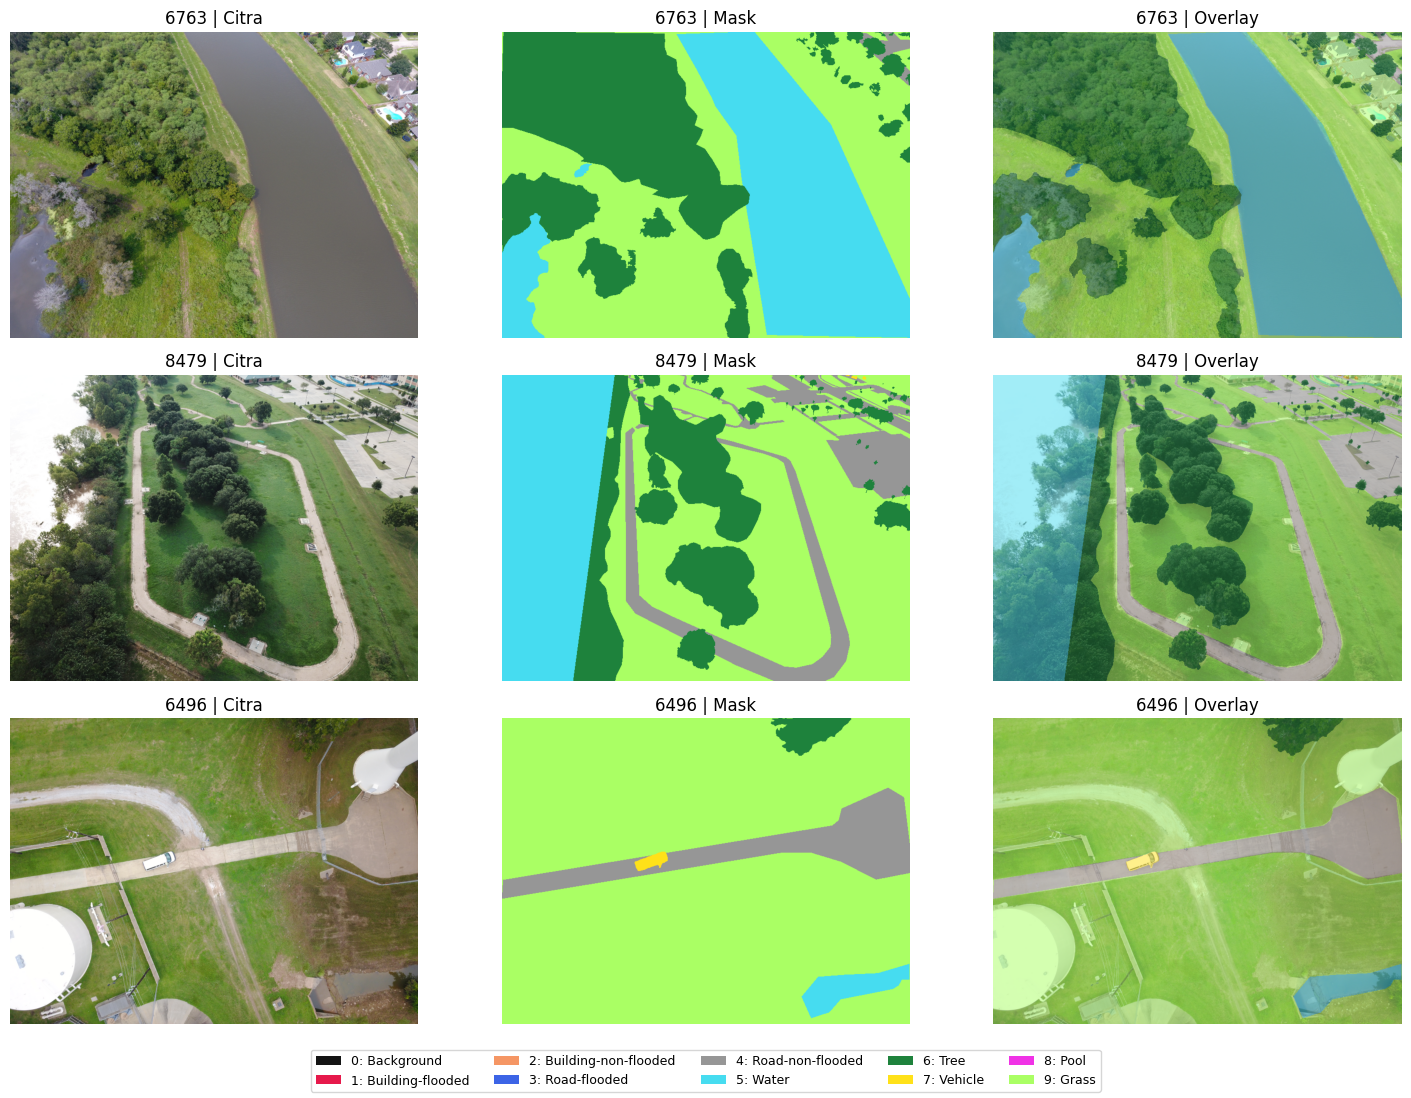

In [4]:
# Contoh citra, mask, dan overlay. Memastikan ID kelas sesuai warna (mis. 5 = Water biru muda, 6 = Tree hijau tua, 9 = Grass hijau muda)
def overlay(img_rgb, msk, alpha=0.5):
    col = colorize(msk)
    ok = (msk < NUM_CLASSES)[..., None]
    return np.where(ok, ((1 - alpha) * img_rgb + alpha * col).astype(np.uint8), img_rgb)

rng = random.Random(1)
samples = rng.sample(SPLITS["train"], 3)
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for r, (k, ip, mp) in enumerate(samples):
    im = cv2.cvtColor(cv2.imread(str(ip)), cv2.COLOR_BGR2RGB)
    mk = read_mask(mp)
    if mk.shape != im.shape[:2]:
        mk = cv2.resize(mk, (im.shape[1], im.shape[0]), interpolation=cv2.INTER_NEAREST)
    s = 800 / max(im.shape[:2])
    im_s = cv2.resize(im, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
    mk_s = cv2.resize(mk, (im_s.shape[1], im_s.shape[0]), interpolation=cv2.INTER_NEAREST)
    for c, (t, a) in enumerate([("Citra", im_s), ("Mask", colorize(mk_s)), ("Overlay", overlay(im_s, mk_s))]):
        axes[r, c].imshow(a); axes[r, c].set_title(f"{k} | {t}"); axes[r, c].axis("off")
fig.legend(handles=LEGEND, loc="lower center", ncol=5, fontsize=9)
plt.tight_layout(rect=(0, 0.05, 1, 1)); savefig("00_visual_check"); plt.show()

## 3. Preprocessing dan cache

Citra asli FloodNet berukuran sekitar 4000×3000 piksel; men-decode JPEG sebesar itu di setiap iterasi membuat GPU menunggu CPU. Karena itu semua citra **di-resize sekali** (sisi panjang = `CACHE_LONG_SIDE`, rasio aspek dipertahankan; citra memakai `INTER_AREA`, mask memakai `NEAREST`) dan disimpan ke cache. Status setiap pasangan (`ok`, `mask_resized`, `skipped_mismatch`, `error`) dicatat di `index.csv` sehingga tidak ada data yang hilang tanpa jejak, dan distribusi piksel per kelas dihitung untuk melihat ketidakseimbangan kelas.

In [5]:
LONG = CFG["CACHE_LONG_SIDE"]
INDEX_CSV = CACHE_DIR / "index.csv"

def process_pair(job):
    split, key, ip, mp = job
    out_i = CACHE_DIR / split / "img" / f"{key}.jpg"
    out_m = CACHE_DIR / split / "msk" / f"{key}.png"
    rec = dict(split=split, key=key, img_src=str(ip), msk_src=str(mp), status="ok")
    try:
        img = cv2.imread(str(ip), cv2.IMREAD_COLOR)
        msk = read_mask(mp)
        ih, iw = img.shape[:2]; mh, mw = msk.shape[:2]
        rec.update(orig_h=ih, orig_w=iw, mask_h=mh, mask_w=mw)
        if (ih, iw) != (mh, mw):
            same_aspect = abs(ih / iw - mh / mw) / (ih / iw) < 0.01
            pol = CFG["MISMATCH_POLICY"]
            if pol == "resize_always" or (pol == "resize_if_same_aspect" and same_aspect):
                msk = cv2.resize(msk, (iw, ih), interpolation=cv2.INTER_NEAREST)
                rec["status"] = "mask_resized"
            else:
                rec["status"] = "skipped_mismatch"
                return rec
        invalid = msk >= NUM_CLASSES
        rec["n_invalid_px"] = int(invalid.sum())
        msk = np.where(invalid, IGNORE, msk).astype(np.uint8)
        s = LONG / max(ih, iw)
        nw, nh = int(round(iw * s)), int(round(ih * s))
        img = cv2.resize(img, (nw, nh), interpolation=cv2.INTER_AREA if s < 1 else cv2.INTER_CUBIC)
        msk = cv2.resize(msk, (nw, nh), interpolation=cv2.INTER_NEAREST)
        out_i.parent.mkdir(parents=True, exist_ok=True); out_m.parent.mkdir(parents=True, exist_ok=True)
        cv2.imwrite(str(out_i), img, [cv2.IMWRITE_JPEG_QUALITY, 95])
        cv2.imwrite(str(out_m), msk)
        cnt = np.bincount(msk.ravel(), minlength=256)
        for c in range(NUM_CLASSES):
            rec[f"c{c}"] = int(cnt[c])
        rec["c_ignore"] = int(cnt[IGNORE])
        rec["cache_img"], rec["cache_msk"] = str(out_i), str(out_m)
    except Exception as e:
        rec["status"] = f"error:{type(e).__name__}:{str(e)[:120]}"
    return rec

# Cache per resolusi: bila index.csv sudah ada, hasil preprocessing dipakai ulang tanpa diproses lagi.
if INDEX_CSV.exists():
    index_df = pd.read_csv(INDEX_CSV)
    print("Cache ditemukan, dipakai ulang:", INDEX_CSV, f"({len(index_df)} baris).")
else:
    jobs = [(s, k, ip, mp) for s, prs in SPLITS.items() for (k, ip, mp) in prs]
    t0 = time.time()
    with ThreadPoolExecutor(max_workers=max(1, min(4, os.cpu_count() or 1))) as ex:
        recs = list(tqdm(ex.map(process_pair, jobs), total=len(jobs), desc="Cache"))
    index_df = pd.DataFrame(recs)
    CACHE_DIR.mkdir(parents=True, exist_ok=True)
    index_df.to_csv(INDEX_CSV, index=False)
    print(f"Selesai dalam {time.time()-t0:.0f} dtk -> {INDEX_CSV}")

status_tbl = index_df.assign(status_group=index_df.status.str.split(":").str[0]) \
                     .groupby(["split", "status_group"]).size().unstack(fill_value=0)
print("\nStatus pasangan citra-mask per split:")
print(status_tbl)
bad = index_df[~index_df.status.isin(["ok", "mask_resized"])]
if len(bad):
    bad.to_csv(EXP_DIR / "excluded_pairs.csv", index=False)
    print(f"\n>> {len(bad)} pasangan dikeluarkan (daftar: {EXP_DIR/'excluded_pairs.csv'}).")
if "n_invalid_px" in index_df and index_df.n_invalid_px.fillna(0).sum() > 0:
    print(f">> {int(index_df.n_invalid_px.sum())} piksel bernilai label tidak valid dijadikan IGNORE.")

USABLE = index_df[index_df.status.isin(["ok", "mask_resized"])]
ITEMS = {s: list(zip(g.cache_img, g.cache_msk)) for s, g in USABLE.groupby("split")}
used = {s: len(v) for s, v in ITEMS.items()}
print("\nItem yang dipakai:", used)
assert used == EXPECTED_SPLIT_SIZES, f"Item yang dipakai {used} berbeda dari split resmi {EXPECTED_SPLIT_SIZES}; pasangan yang dikeluarkan tercatat di excluded_pairs.csv."

Cache:   0%|          | 0/2343 [00:00<?, ?it/s]

Selesai dalam 396 dtk -> /kaggle/working/cache_1024/index.csv

Status pasangan citra-mask per split:
status_group    ok
split             
test           448
train         1445
val            450

Item yang dipakai: {'test': 448, 'train': 1445, 'val': 450}


               kelas  persen_piksel
          Background           1.71
    Building-flooded           1.42
Building-non-flooded           3.28
        Road-flooded           2.50
    Road-non-flooded           5.57
               Water          10.82
                Tree          17.45
             Vehicle           0.17
                Pool           0.20
               Grass          56.88


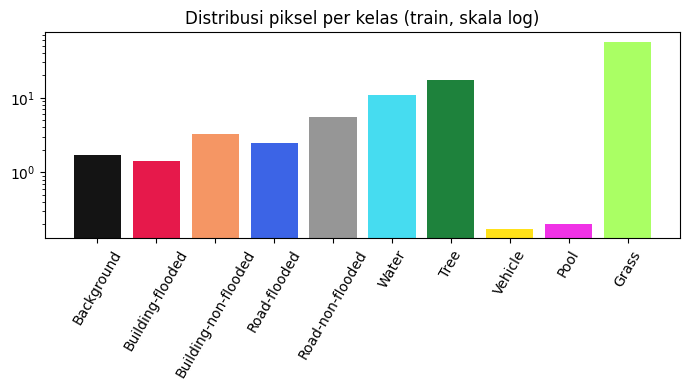

In [6]:
# ---- Distribusi kelas (train) ----
tr = USABLE[USABLE.split == "train"]
counts = np.array([tr[f"c{k}"].sum() for k in range(NUM_CLASSES)], dtype=np.float64)
share = counts / counts.sum()

dist = pd.DataFrame({"kelas": CLASS_NAMES, "persen_piksel": (share * 100).round(2)})
print(dist.to_string(index=False))
dist.to_csv(EXP_DIR / "class_distribution.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(CLASS_NAMES, share * 100, color=PALETTE / 255); ax.set_yscale("log")
ax.set_title("Distribusi piksel per kelas (train, skala log)"); ax.tick_params(axis="x", rotation=60)
plt.tight_layout(); savefig("01_class_distribution"); plt.show()


## 4. Dataset, augmentasi, dan DataLoader

Augmentasi ditulis manual dengan OpenCV/NumPy (tanpa dependensi `albumentations`, supaya tidak terganggu perbedaan versi API). Urutannya: skala acak → padding (`IGNORE` pada mask) → **crop sadar kelas langka** → fotometrik ringan. Hue tidak diubah karena warna air banjir (cokelat) dan air alami adalah petunjuk penting; flip dan rotasi tidak dipakai.

In [7]:
RARE_LUT = np.zeros(256, bool); RARE_LUT[CFG["RARE_CLASSES"]] = True

def augment(img, msk):
    crop = CFG["CROP"]
    # 1) skala acak
    s = random.uniform(*CFG["SCALE_RANGE"])
    if abs(s - 1) > 1e-3:
        h, w = msk.shape
        nh, nw = int(h * s + 0.5), int(w * s + 0.5)
        img = cv2.resize(img, (nw, nh), interpolation=cv2.INTER_LINEAR if s > 1 else cv2.INTER_AREA)
        msk = cv2.resize(msk, (nw, nh), interpolation=cv2.INTER_NEAREST)
    # 2) padding jika lebih kecil dari crop (mask diisi IGNORE)
    h, w = msk.shape
    ph, pw = max(crop - h, 0), max(crop - w, 0)
    if ph or pw:
        img = cv2.copyMakeBorder(img, 0, ph, 0, pw, cv2.BORDER_CONSTANT, value=(0, 0, 0))
        msk = cv2.copyMakeBorder(msk, 0, ph, 0, pw, cv2.BORDER_CONSTANT, value=IGNORE)
        h, w = msk.shape
    # 3) crop: dengan peluang RARE_CROP_PROB, crop dipusatkan pada piksel kelas langka
    y0 = x0 = None
    if random.random() < CFG["RARE_CROP_PROB"]:
        ys, xs = np.nonzero(RARE_LUT[msk])
        if len(ys):
            k = random.randrange(len(ys))
            j = crop // 4
            y0 = int(np.clip(ys[k] - crop // 2 + random.randint(-j, j), 0, h - crop))
            x0 = int(np.clip(xs[k] - crop // 2 + random.randint(-j, j), 0, w - crop))
    if y0 is None:
        y0 = random.randint(0, h - crop); x0 = random.randint(0, w - crop)
    img = img[y0:y0 + crop, x0:x0 + crop]; msk = msk[y0:y0 + crop, x0:x0 + crop]
    img, msk = np.ascontiguousarray(img), np.ascontiguousarray(msk)
    # 4) fotometrik ringan (tanpa perubahan hue: warna air banjir vs air alami adalah petunjuk penting)
    if random.random() < 0.8:
        img = np.clip(img.astype(np.float32) * random.uniform(0.75, 1.25) + random.uniform(-25, 25), 0, 255).astype(np.uint8)
    if random.random() < 0.3:
        hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV).astype(np.float32)
        hsv[..., 1] = np.clip(hsv[..., 1] * random.uniform(0.7, 1.3), 0, 255)
        img = cv2.cvtColor(hsv.astype(np.uint8), cv2.COLOR_HSV2RGB)
    if random.random() < 0.2:
        k = random.choice([3, 5]); img = cv2.GaussianBlur(img, (k, k), 0)
    if random.random() < 0.2:
        img = np.clip(img.astype(np.float32) + np.random.normal(0, random.uniform(2, 8), img.shape), 0, 255).astype(np.uint8)
    return img, msk

def to_tensor(img):
    x = (img.astype(np.float32) / 255.0 - MEAN) / STD
    return torch.from_numpy(np.ascontiguousarray(x.transpose(2, 0, 1)))

class FloodNetDS(Dataset):
    def __init__(self, items, train):
        self.items, self.train = items, train
    def __len__(self):
        return len(self.items)
    def __getitem__(self, i):
        ip, mp = self.items[i]
        img = cv2.cvtColor(cv2.imread(ip, cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)
        msk = cv2.imread(mp, cv2.IMREAD_GRAYSCALE)
        if self.train:
            img, msk = augment(img, msk)
        return to_tensor(img), torch.from_numpy(msk.astype(np.int64))

def _worker_init(wid):
    s = CFG["SEED"] + wid; random.seed(s); np.random.seed(s)

nw = CFG["NUM_WORKERS"]
train_ds = FloodNetDS(ITEMS["train"], train=True)
val_ds   = FloodNetDS(ITEMS["val"], train=False)
test_ds  = FloodNetDS(ITEMS["test"], train=False) if "test" in ITEMS else None
train_loader = DataLoader(train_ds, batch_size=CFG["BATCH_SIZE"], shuffle=True, drop_last=True, num_workers=nw,
                          pin_memory=device.type == "cuda", persistent_workers=nw > 0, worker_init_fn=_worker_init)
val_loader  = DataLoader(val_ds, batch_size=1, shuffle=False, num_workers=min(2, nw), pin_memory=device.type == "cuda")
test_loader = DataLoader(test_ds, batch_size=1, shuffle=False, num_workers=min(2, nw), pin_memory=device.type == "cuda") if test_ds else None
print(f"train={len(train_ds)} ({len(train_loader)} iter/epoch) | val={len(val_ds)} | test={len(test_ds) if test_ds else 0}")

train=1445 (361 iter/epoch) | val=450 | test=448


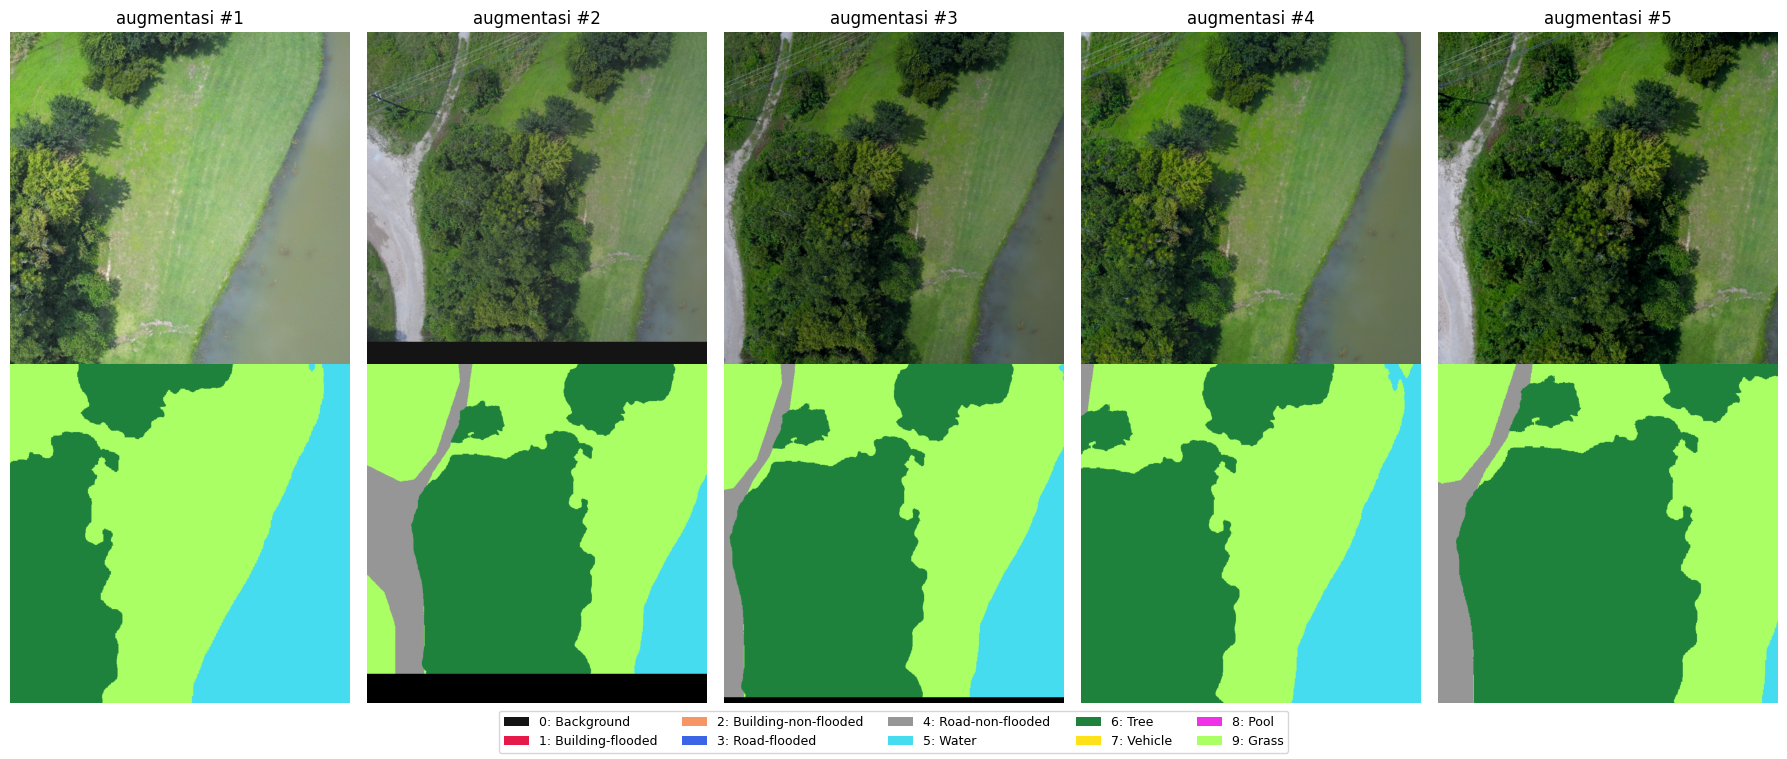

In [8]:
# Contoh hasil augmentasi: baris atas = citra, baris bawah = mask
random.seed(0)
ip, mp = random.choice(ITEMS["train"])
img0 = cv2.cvtColor(cv2.imread(ip), cv2.COLOR_BGR2RGB); msk0 = cv2.imread(mp, cv2.IMREAD_GRAYSCALE)
fig, axes = plt.subplots(2, 5, figsize=(18, 7.5))
for j in range(5):
    a_img, a_msk = augment(img0.copy(), msk0.copy())
    axes[0, j].imshow(a_img); axes[0, j].axis("off"); axes[0, j].set_title(f"augmentasi #{j+1}")
    axes[1, j].imshow(colorize(a_msk)); axes[1, j].axis("off")
fig.legend(handles=LEGEND, loc="lower center", ncol=5, fontsize=9)
plt.tight_layout(rect=(0, 0.05, 1, 1)); savefig("02_augmentation_check"); plt.show()
set_seed(CFG["SEED"])

## 5. Model, loss, dan metrik

**Model.** UPerNet dengan encoder ConvNeXt-Nano, dibangun lewat `segmentation_models_pytorch`: `smp.UPerNet("tu-convnext_nano.d1h_in1k", decoder_channels=128)`. Jumlah parameternya 17,72 juta, terdiri atas dua bagian.

* **Encoder ConvNeXt-Nano** (timm, tag `d1h_in1k`), diinisialisasi dari bobot ImageNet-1k. Tag dipilih eksplisit agar bobot yang dimuat hanya hasil pretraining ImageNet-1k. Encoder hierarkis ini memiliki empat tahap (kedalaman 2, 2, 8, 2 blok; lebar kanal 80, 160, 320, 640) dan menghasilkan fitur pada stride 4, 8, 16, dan 32 (s4, s8, s16, s32). Tiap blok memakai konvolusi depthwise 7×7, LayerNorm, dan MLP inverted-bottleneck dengan aktivasi GELU.
* **Decoder UPerNet** selebar `DEC_CH` (128) kanal, dilatih dari awal, dengan alur berikut: (1) tiap fitur encoder dinormalisasi dengan LayerNorm; (2) *Pyramid Pooling Module* (PSP) pada fitur s32 mengumpulkan konteks global lewat *adaptive average pooling* berukuran 1, 2, 3, dan 6, masing-masing diproyeksi 1×1 (Conv-BatchNorm-ReLU), di-*upsample*, di-*concat* dengan fitur asal, lalu digabung konvolusi 3×3; (3) jalur *Feature Pyramid Network* (FPN) top-down: fitur s4, s8, s16 diproyeksi lateral 1×1 ke `DEC_CH` kanal, ditambahkan dengan level di atasnya yang sudah di-*upsample*, lalu dihaluskan blok Conv-BatchNorm-ReLU; (4) keempat level di-*upsample* ke s4, di-*concat*, dan digabung oleh blok fusi.
* **Segmentation head** memproyeksikan hasil fusi s4 ke 10 kelas, lalu meng-*upsample* bilinear ×4 sehingga logit keluaran sudah berada pada resolusi input. `SegWrapper` hanya menambahkan autocast fp16 dan memastikan ukuran logit sama dengan input.

Pembagian learning rate: parameter pada atribut `encoder` memakai `LR_ENCODER`, sedangkan `decoder` dan `segmentation_head` memakai `LR_DECODER` (ditentukan oleh `DECODER_KEYS`). Decoder memakai blok Conv-BatchNorm-ReLU bawaan smp; statistik BatchNorm dihitung per batch (4 crop) dan buffernya ikut diperbarui oleh EMA.

**Loss.** Cross-Entropy dan Dice (masing-masing 0,5) dengan piksel `IGNORE` diabaikan; Dice dihitung hanya untuk kelas yang ada di batch.

**Metrik.** Dihitung dari confusion matrix (baris = ground truth, kolom = prediksi) dan dilaporkan pada bagian 7.

In [9]:
class SegWrapper(nn.Module):
    def __init__(self, net):
        super().__init__()
        self.net = net
    def forward(self, x):
        with torch.autocast(x.device.type, dtype=torch.float16, enabled=USE_AMP):
            out = self.net(x)                       # smp.UPerNet sudah mengembalikan logit resolusi penuh
        if out.shape[-2:] != x.shape[-2:]:
            out = F.interpolate(out, size=x.shape[-2:], mode="bilinear", align_corners=False)
        return out


# Model: UPerNet (PSP + FPN) dengan encoder ConvNeXt-Nano, dibangun lewat segmentation_models_pytorch (smp).
# Encoder berada di atribut `encoder` (memakai LR_ENCODER); `decoder` dan `segmentation_head` memakai LR_DECODER (ditentukan oleh DECODER_KEYS).
def build_upernet(dec_ch):
    return smp.UPerNet(
        CFG["ENCODER"],                                          # "tu-convnext_nano.d1h_in1k": ConvNeXt-Nano dari timm
        encoder_weights=True if CFG["PRETRAINED"] else None,     # bobot ImageNet-1k untuk encoder
        classes=NUM_CLASSES,
        decoder_channels=dec_ch,                                 # lebar decoder (PSP, FPN, dan fusi s4)
    )

DECODER_KEYS = ("decoder", "segmentation_head")   # parameter dengan nama berisi salah satu kunci ini memakai LR_DECODER; parameter lain dianggap encoder


def make_param_groups(model, lr_enc, lr_dec, wd):
    groups = {(e, d): [] for e in (True, False) for d in (True, False)}   # (is_encoder, apply_decay)
    for n, p in model.named_parameters():
        if p.requires_grad:
            is_dec = any(k in n for k in DECODER_KEYS)
            groups[(not is_dec, p.ndim > 1)].append(p)
    out = []
    for (is_enc, decay), ps in groups.items():
        if ps:
            lr = lr_enc if is_enc else lr_dec
            out.append(dict(params=ps, lr=lr, base_lr=lr, weight_decay=wd if decay else 0.0))
    return out


model = SegWrapper(build_upernet(CFG["DEC_CH"])).to(device)
n_params = sum(p.numel() for p in model.parameters()) / 1e6
print(f"Model: {CFG['MODEL']} | parameter: {n_params:.2f} juta")
_pg = make_param_groups(model, CFG["LR_ENCODER"], CFG["LR_DECODER"], CFG["WEIGHT_DECAY"])
_enc = sum(p.numel() for g in _pg if g["base_lr"] == CFG["LR_ENCODER"] for p in g["params"]) / 1e6
_dec = sum(p.numel() for g in _pg if g["base_lr"] == CFG["LR_DECODER"] for p in g["params"]) / 1e6
print(f"Grup parameter -> encoder: {_enc:.2f} jt (lr {CFG['LR_ENCODER']}) | decoder: {_dec:.2f} jt (lr {CFG['LR_DECODER']})")
assert _enc > 0 and _dec > 0, "Pembagian parameter encoder/decoder gagal: salah satu grup kosong."


import copy
class EMA:
    def __init__(self, m, decay):
        self.decay, self.n = decay, 0
        self.module = copy.deepcopy(m).eval()
        for p in self.module.parameters():
            p.requires_grad_(False)
    @torch.no_grad()
    def update(self, m):
        self.n += 1
        d = min(self.decay, (1 + self.n) / (10 + self.n))
        src = m.state_dict()
        for k, v in self.module.state_dict().items():
            if v.dtype.is_floating_point:
                v.mul_(d).add_(src[k].detach(), alpha=1 - d)
            else:
                v.copy_(src[k])


model.safetensors: reconstructing file:   0%|          |  0.00B / 62.4MB            

model.safetensors: downloading bytes:           |  0.00B            

Model: upernet-convnext-nano | parameter: 17.72 juta
Grup parameter -> encoder: 14.95 jt (lr 3e-05) | decoder: 2.77 jt (lr 0.0003)


In [10]:
class CEDiceLoss(nn.Module):
    def __init__(self, ce_w=0.5, dice_w=0.5, ignore_index=IGNORE, eps=1.0):
        super().__init__()
        self.ce_w, self.dice_w, self.ignore, self.eps = ce_w, dice_w, ignore_index, eps
    def forward(self, logits, target):
        logits = logits.float()
        ce = F.cross_entropy(logits, target, ignore_index=self.ignore)
        valid = (target != self.ignore)
        tgt = target.masked_fill(~valid, 0)
        v = valid.unsqueeze(1).float()
        prob = logits.softmax(1) * v
        oh = F.one_hot(tgt, logits.shape[1]).permute(0, 3, 1, 2).float() * v
        inter = (prob * oh).sum((0, 2, 3))
        denom = prob.sum((0, 2, 3)) + oh.sum((0, 2, 3))
        present = oh.sum((0, 2, 3)) > 0                       # hanya kelas yang ada di batch
        dice = (2 * inter + self.eps) / (denom + self.eps)
        dloss = 1 - dice[present].mean() if present.any() else logits.sum() * 0
        return self.ce_w * ce + self.dice_w * dloss

class ConfMat:
    # baris = ground truth, kolom = prediksi
    def __init__(self, C=NUM_CLASSES):
        self.C = C; self.m = torch.zeros(C, C, dtype=torch.long, device=device)
    def update(self, pred, target):
        k = target != IGNORE
        idx = target[k] * self.C + pred[k]
        self.m += torch.bincount(idx, minlength=self.C ** 2).reshape(self.C, self.C)
    def compute(self):
        cm = self.m.double().cpu().numpy()
        tp = np.diag(cm); fp = cm.sum(0) - tp; fn = cm.sum(1) - tp
        with np.errstate(divide="ignore", invalid="ignore"):
            iou = tp / (tp + fp + fn); f1 = 2 * tp / (2 * tp + fp + fn)
            prec = tp / (tp + fp); rec = tp / (tp + fn)
        # miou = rata-rata IoU 10 kelas; miou_nobg = rata-rata IoU kelas 1-9 (Background tetap ada di confusion matrix)
        return dict(cm=cm, iou=iou, f1=f1, precision=prec, recall=rec,
                    miou=float(np.nanmean(iou)), miou_nobg=float(np.nanmean(iou[1:])),
                    mf1=float(np.nanmean(f1)), pixacc=float(tp.sum() / cm.sum()))

def forward_padded(model, x, mult=32):   # mult = stride terbesar encoder (s32)
    _, _, H, W = x.shape
    ph, pw = (mult - H % mult) % mult, (mult - W % mult) % mult
    if ph or pw:
        x = F.pad(x, (0, pw, 0, ph))
    return model(x)[..., :H, :W]

@torch.no_grad()
def predict_probs(model, x):
    with torch.autocast(device.type, dtype=torch.float16, enabled=USE_AMP):
        lg = forward_padded(model, x)
    return lg.float().softmax(1)

@torch.no_grad()
def evaluate(model, loader, desc="Eval"):
    model.eval(); cm = ConfMat()
    for x, y in tqdm(loader, desc=desc, leave=False):
        x, y = x.to(device), y.to(device)
        cm.update(predict_probs(model, x).argmax(1), y)
    return cm.compute()

criterion = CEDiceLoss(CFG["CE_WEIGHT"], CFG["DICE_WEIGHT"]).to(device)
print("Loss & metrik siap.")

Loss & metrik siap.


## 6. Training

* AdamW dengan learning rate terpisah untuk encoder dan decoder, warmup linear lalu poly decay, AMP fp16, *gradient clipping*, dan EMA bobot.
* Evaluasi pada validation set setiap `EVAL_EVERY` epoch. Model terbaik dipilih berdasarkan **mIoU 9 kelas (tanpa Background) pada validation set** (bukan test) dan disimpan sebagai `best.pt` (bobot EMA).
* Tanpa *early stopping*: training berjalan penuh sampai `EPOCHS`.

In [11]:
opt = torch.optim.AdamW(make_param_groups(model, CFG["LR_ENCODER"], CFG["LR_DECODER"], CFG["WEIGHT_DECAY"]))
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
ema = EMA(model, CFG["EMA_DECAY"])
eval_net = ema.module         # bobot yang dievaluasi dan disimpan sebagai best.pt

EPOCHS = CFG["EPOCHS"]
TOTAL_IT = EPOCHS * len(train_loader)
WARM = min(CFG["WARMUP_ITERS"], max(1, TOTAL_IT // 10))

def lr_factor(it):
    if it < WARM:
        return (it + 1) / WARM
    p = (it - WARM) / max(1, TOTAL_IT - WARM)
    return max(0.0, (1 - p) ** CFG["POLY_POWER"])

BEST_PT = EXP_DIR / "best.pt"
state = dict(it=0, best=-1.0, history=[])

def train_one_epoch(ep):
    model.train(); tot, n = 0.0, 0
    pbar = tqdm(train_loader, desc=f"Epoch {ep}/{EPOCHS}", leave=False)
    for x, y in pbar:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        f = lr_factor(state["it"])
        for g in opt.param_groups:
            g["lr"] = g["base_lr"] * f
        logits = model(x)
        loss = criterion(logits, y.to(logits.device))
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(model.parameters(), CFG["GRAD_CLIP"])
        scaler.step(opt); scaler.update()
        ema.update(model)
        state["it"] += 1; tot += loss.item(); n += 1
        pbar.set_postfix(loss=f"{tot/n:.4f}", lr=f"{opt.param_groups[0]['lr']:.1e}")
    return tot / max(n, 1)

# mIoU9 = rata-rata IoU kelas 1-9 (tanpa Background); mIoU10 = rata-rata IoU 10 kelas
t_start = time.time()
for ep in range(1, EPOCHS + 1):
    t0 = time.time()
    tr_loss = train_one_epoch(ep)
    row = dict(epoch=ep, train_loss=tr_loss, lr=opt.param_groups[0]["lr"], val_miou=np.nan, val_miou_nobg=np.nan, val_pixacc=np.nan)
    if ep % CFG["EVAL_EVERY"] == 0 or ep == EPOCHS:
        r = evaluate(eval_net, val_loader, desc=f"Val ep{ep}")
        row.update(val_miou=r["miou"], val_miou_nobg=r["miou_nobg"], val_pixacc=r["pixacc"])
        if r["miou_nobg"] > state["best"]:   # checkpoint terbaik dipilih dari mIoU 9 kelas pada validation
            state["best"] = r["miou_nobg"]
            torch.save(dict(model=eval_net.state_dict(), epoch=ep, val_miou=r["miou"], val_miou_nobg=r["miou_nobg"], cfg=CFG), BEST_PT)
            tag = "  * best"
        else:
            tag = ""
        print(f"ep {ep:3d} | loss {tr_loss:.4f} | val mIoU9 {r['miou_nobg']:.4f} | mIoU10 {r['miou']:.4f} | "
              f"pixAcc {r['pixacc']:.4f} | {time.time()-t0:.0f}s{tag}")
    else:
        print(f"ep {ep:3d} | loss {tr_loss:.4f} | {time.time()-t0:.0f}s")
    state["history"].append(row)
    pd.DataFrame(state["history"]).to_csv(EXP_DIR / "history.csv", index=False)

print(f"\nSelesai. Waktu total {(time.time()-t_start)/60:.1f} menit | best val mIoU 9 kelas = {state['best']:.4f}")

Epoch 1/100:   0%|          | 0/361 [00:00<?, ?it/s]

ep   1 | loss 0.7206 | 123s


Epoch 2/100:   0%|          | 0/361 [00:00<?, ?it/s]

Val ep2:   0%|          | 0/450 [00:00<?, ?it/s]

ep   2 | loss 0.3880 | val mIoU9 0.7053 | mIoU10 0.6348 | pixAcc 0.8895 | 138s  * best


Epoch 3/100:   0%|          | 0/361 [00:00<?, ?it/s]

... (240 outputs left out)

ep  99 | loss 0.0530 | 118s


Epoch 100/100:   0%|          | 0/361 [00:00<?, ?it/s]

Val ep100:   0%|          | 0/450 [00:00<?, ?it/s]

ep 100 | loss 0.0547 | val mIoU9 0.7914 | mIoU10 0.7733 | pixAcc 0.9218 | 125s

Selesai. Waktu total 202.4 menit | best val mIoU 9 kelas = 0.7927


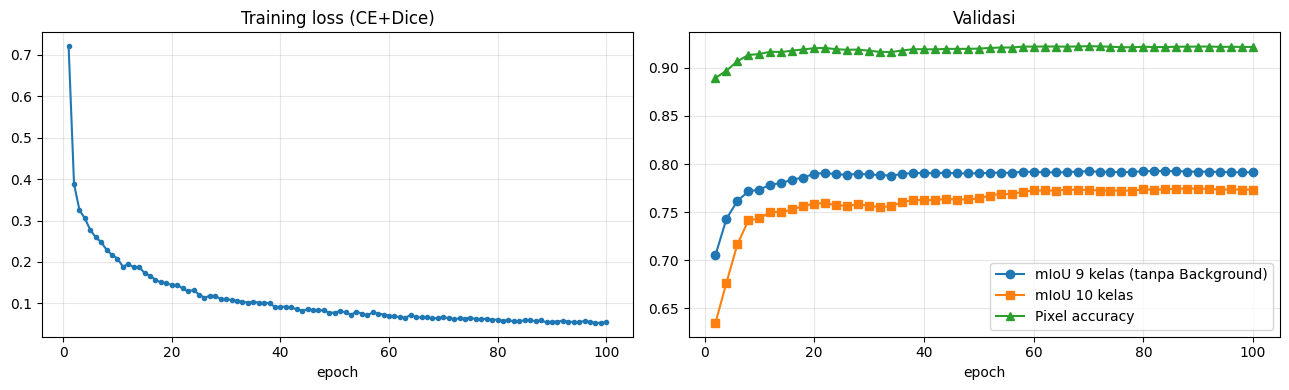

In [12]:
hist = pd.DataFrame(state["history"])
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(hist.epoch, hist.train_loss, marker="o", ms=3); ax[0].set_title("Training loss (CE+Dice)"); ax[0].set_xlabel("epoch"); ax[0].grid(alpha=.3)
v = hist.dropna(subset=["val_miou"])
ax[1].plot(v.epoch, v.val_miou_nobg, marker="o", label="mIoU 9 kelas (tanpa Background)")
ax[1].plot(v.epoch, v.val_miou, marker="s", label="mIoU 10 kelas")
ax[1].plot(v.epoch, v.val_pixacc, marker="^", label="Pixel accuracy")
ax[1].set_title("Validasi"); ax[1].set_xlabel("epoch"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); savefig("03_training_curves"); plt.show()

## 7. Evaluasi

Model terbaik (`best.pt`, dipilih dari **validation**) dievaluasi pada validation dan test set. Test tidak dipakai untuk seleksi model maupun penyetelan parameter apa pun. Prediksi diambil dari `argmax` probabilitas. Dilaporkan:

* **mIoU 9 kelas** (metrik utama): rata-rata IoU kelas 1–9, tanpa Background. Dihitung dari confusion matrix 10 kelas: piksel Background tidak diabaikan, sehingga prediksi yang tertukar dengan Background tetap memengaruhi IoU kelas 1–9,
* **mIoU 10 kelas** (pendamping): rata-rata IoU seluruh kelas termasuk Background,
* Pixel accuracy, mean F1 (10 kelas), serta IoU / F1 / precision / recall per kelas.

In [13]:
ck = torch.load(BEST_PT, map_location=device)
model.load_state_dict(ck["model"]); model.eval()
print(f"Memuat best.pt (epoch {ck['epoch']}, val mIoU 9 kelas saat disimpan = {ck['val_miou_nobg']:.4f})")

RESULTS = {"val": evaluate(model, val_loader, desc="Val")}
if test_loader:
    RESULTS["test"] = evaluate(model, test_loader, desc="Test")

summary = pd.DataFrame({k: {"mIoU 9 kelas": r["miou_nobg"], "mIoU 10 kelas": r["miou"],
                            "mean F1 (10 kelas)": r["mf1"], "Pixel Acc": r["pixacc"]}
                        for k, r in RESULTS.items()}).T.round(4)
print("\n=== HASIL ===")
print(summary.to_string())
summary.to_csv(EXP_DIR / "summary_metrics.csv")

main_key = "test" if "test" in RESULTS else "val"
per_class = pd.DataFrame({"kelas": CLASS_NAMES,
                          **{f"IoU_{k}": r["iou"] for k, r in RESULTS.items()},
                          "F1": RESULTS[main_key]["f1"], "Precision": RESULTS[main_key]["precision"],
                          "Recall": RESULTS[main_key]["recall"]}).round(4)
print(f"\nMetrik per kelas (F1/Precision/Recall dari '{main_key}'):")
print(per_class.to_string(index=False))
per_class.to_csv(EXP_DIR / "per_class_metrics.csv", index=False)


Memuat best.pt (epoch 86, val mIoU 9 kelas saat disimpan = 0.7927)


Val:   0%|          | 0/450 [00:00<?, ?it/s]

Test:   0%|          | 0/448 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e1998dd9620>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
Exception ignored in:   File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
<function _MultiProcessingDataLoaderIter.__del__ at 0x7e1998dd9620>    
assert self._parent_pid == os.getpid(), 'can only test a child process'Traceback (most recent call last):

AssertionError  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
:     can only test a child process
self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/


=== HASIL ===
      mIoU 9 kelas  mIoU 10 kelas  mean F1 (10 kelas)  Pixel Acc
val         0.7927         0.7744              0.8700      0.922
test        0.7830         0.7699              0.8668      0.933

Metrik per kelas (F1/Precision/Recall dari 'test'):
               kelas  IoU_val  IoU_test     F1  Precision  Recall
          Background   0.6096    0.6521 0.7894     0.8120  0.7680
    Building-flooded   0.8008    0.7366 0.8483     0.8196  0.8791
Building-non-flooded   0.8351    0.8322 0.9084     0.9166  0.9004
        Road-flooded   0.6603    0.6566 0.7927     0.7108  0.8959
    Road-non-flooded   0.8521    0.8578 0.9234     0.9185  0.9285
               Water   0.7533    0.8105 0.8953     0.9013  0.8895
                Tree   0.8619    0.8676 0.9291     0.9272  0.9310
             Vehicle   0.7103    0.6693 0.8019     0.7825  0.8222
                Pool   0.7608    0.6976 0.8218     0.8281  0.8157
               Grass   0.8999    0.9192 0.9579     0.9618  0.9540


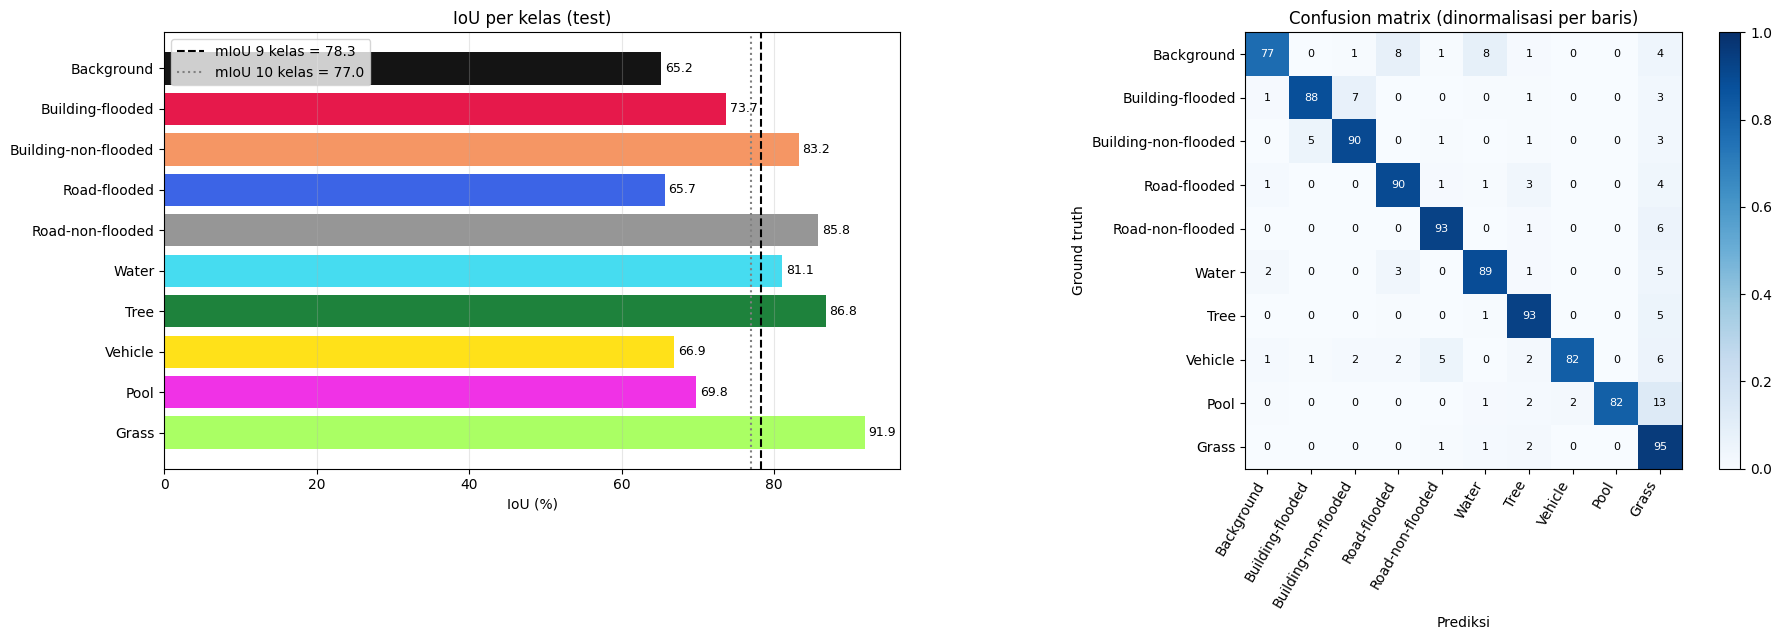

In [14]:
# ---- IoU per kelas & confusion matrix (dinormalisasi per baris = recall) ----
r = RESULTS[main_key]
fig, ax = plt.subplots(1, 2, figsize=(18, 6.5))
bars = ax[0].barh(CLASS_NAMES[::-1], (r["iou"] * 100)[::-1], color=(PALETTE / 255)[::-1])
ax[0].axvline(r["miou_nobg"] * 100, color="k", ls="--", label=f"mIoU 9 kelas = {r['miou_nobg']*100:.1f}")
ax[0].axvline(r["miou"] * 100, color="gray", ls=":", label=f"mIoU 10 kelas = {r['miou']*100:.1f}")
ax[0].set_xlabel("IoU (%)"); ax[0].set_title(f"IoU per kelas ({main_key})"); ax[0].legend(); ax[0].grid(axis="x", alpha=.3)
for b, v in zip(bars, (r["iou"] * 100)[::-1]):
    ax[0].text(v + 0.5, b.get_y() + b.get_height() / 2, f"{v:.1f}", va="center", fontsize=9)

cmn = r["cm"] / np.maximum(r["cm"].sum(1, keepdims=True), 1)
im = ax[1].imshow(cmn, cmap="Blues", vmin=0, vmax=1)
ax[1].set_xticks(range(NUM_CLASSES)); ax[1].set_yticks(range(NUM_CLASSES))
ax[1].set_xticklabels(CLASS_NAMES, rotation=60, ha="right"); ax[1].set_yticklabels(CLASS_NAMES)
ax[1].set_xlabel("Prediksi"); ax[1].set_ylabel("Ground truth"); ax[1].set_title("Confusion matrix (dinormalisasi per baris)")
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        ax[1].text(j, i, f"{cmn[i, j]*100:.0f}", ha="center", va="center", fontsize=8,
                   color="white" if cmn[i, j] > 0.5 else "black")
plt.colorbar(im, ax=ax[1], fraction=0.046); plt.tight_layout(); savefig("04_iou_confusion"); plt.show()

## 8. Visualisasi kualitatif dan efisiensi

Contoh prediksi pada test set, serta kompleksitas model (parameter dan GMACs/GFLOPs) dan kecepatan inferensi.

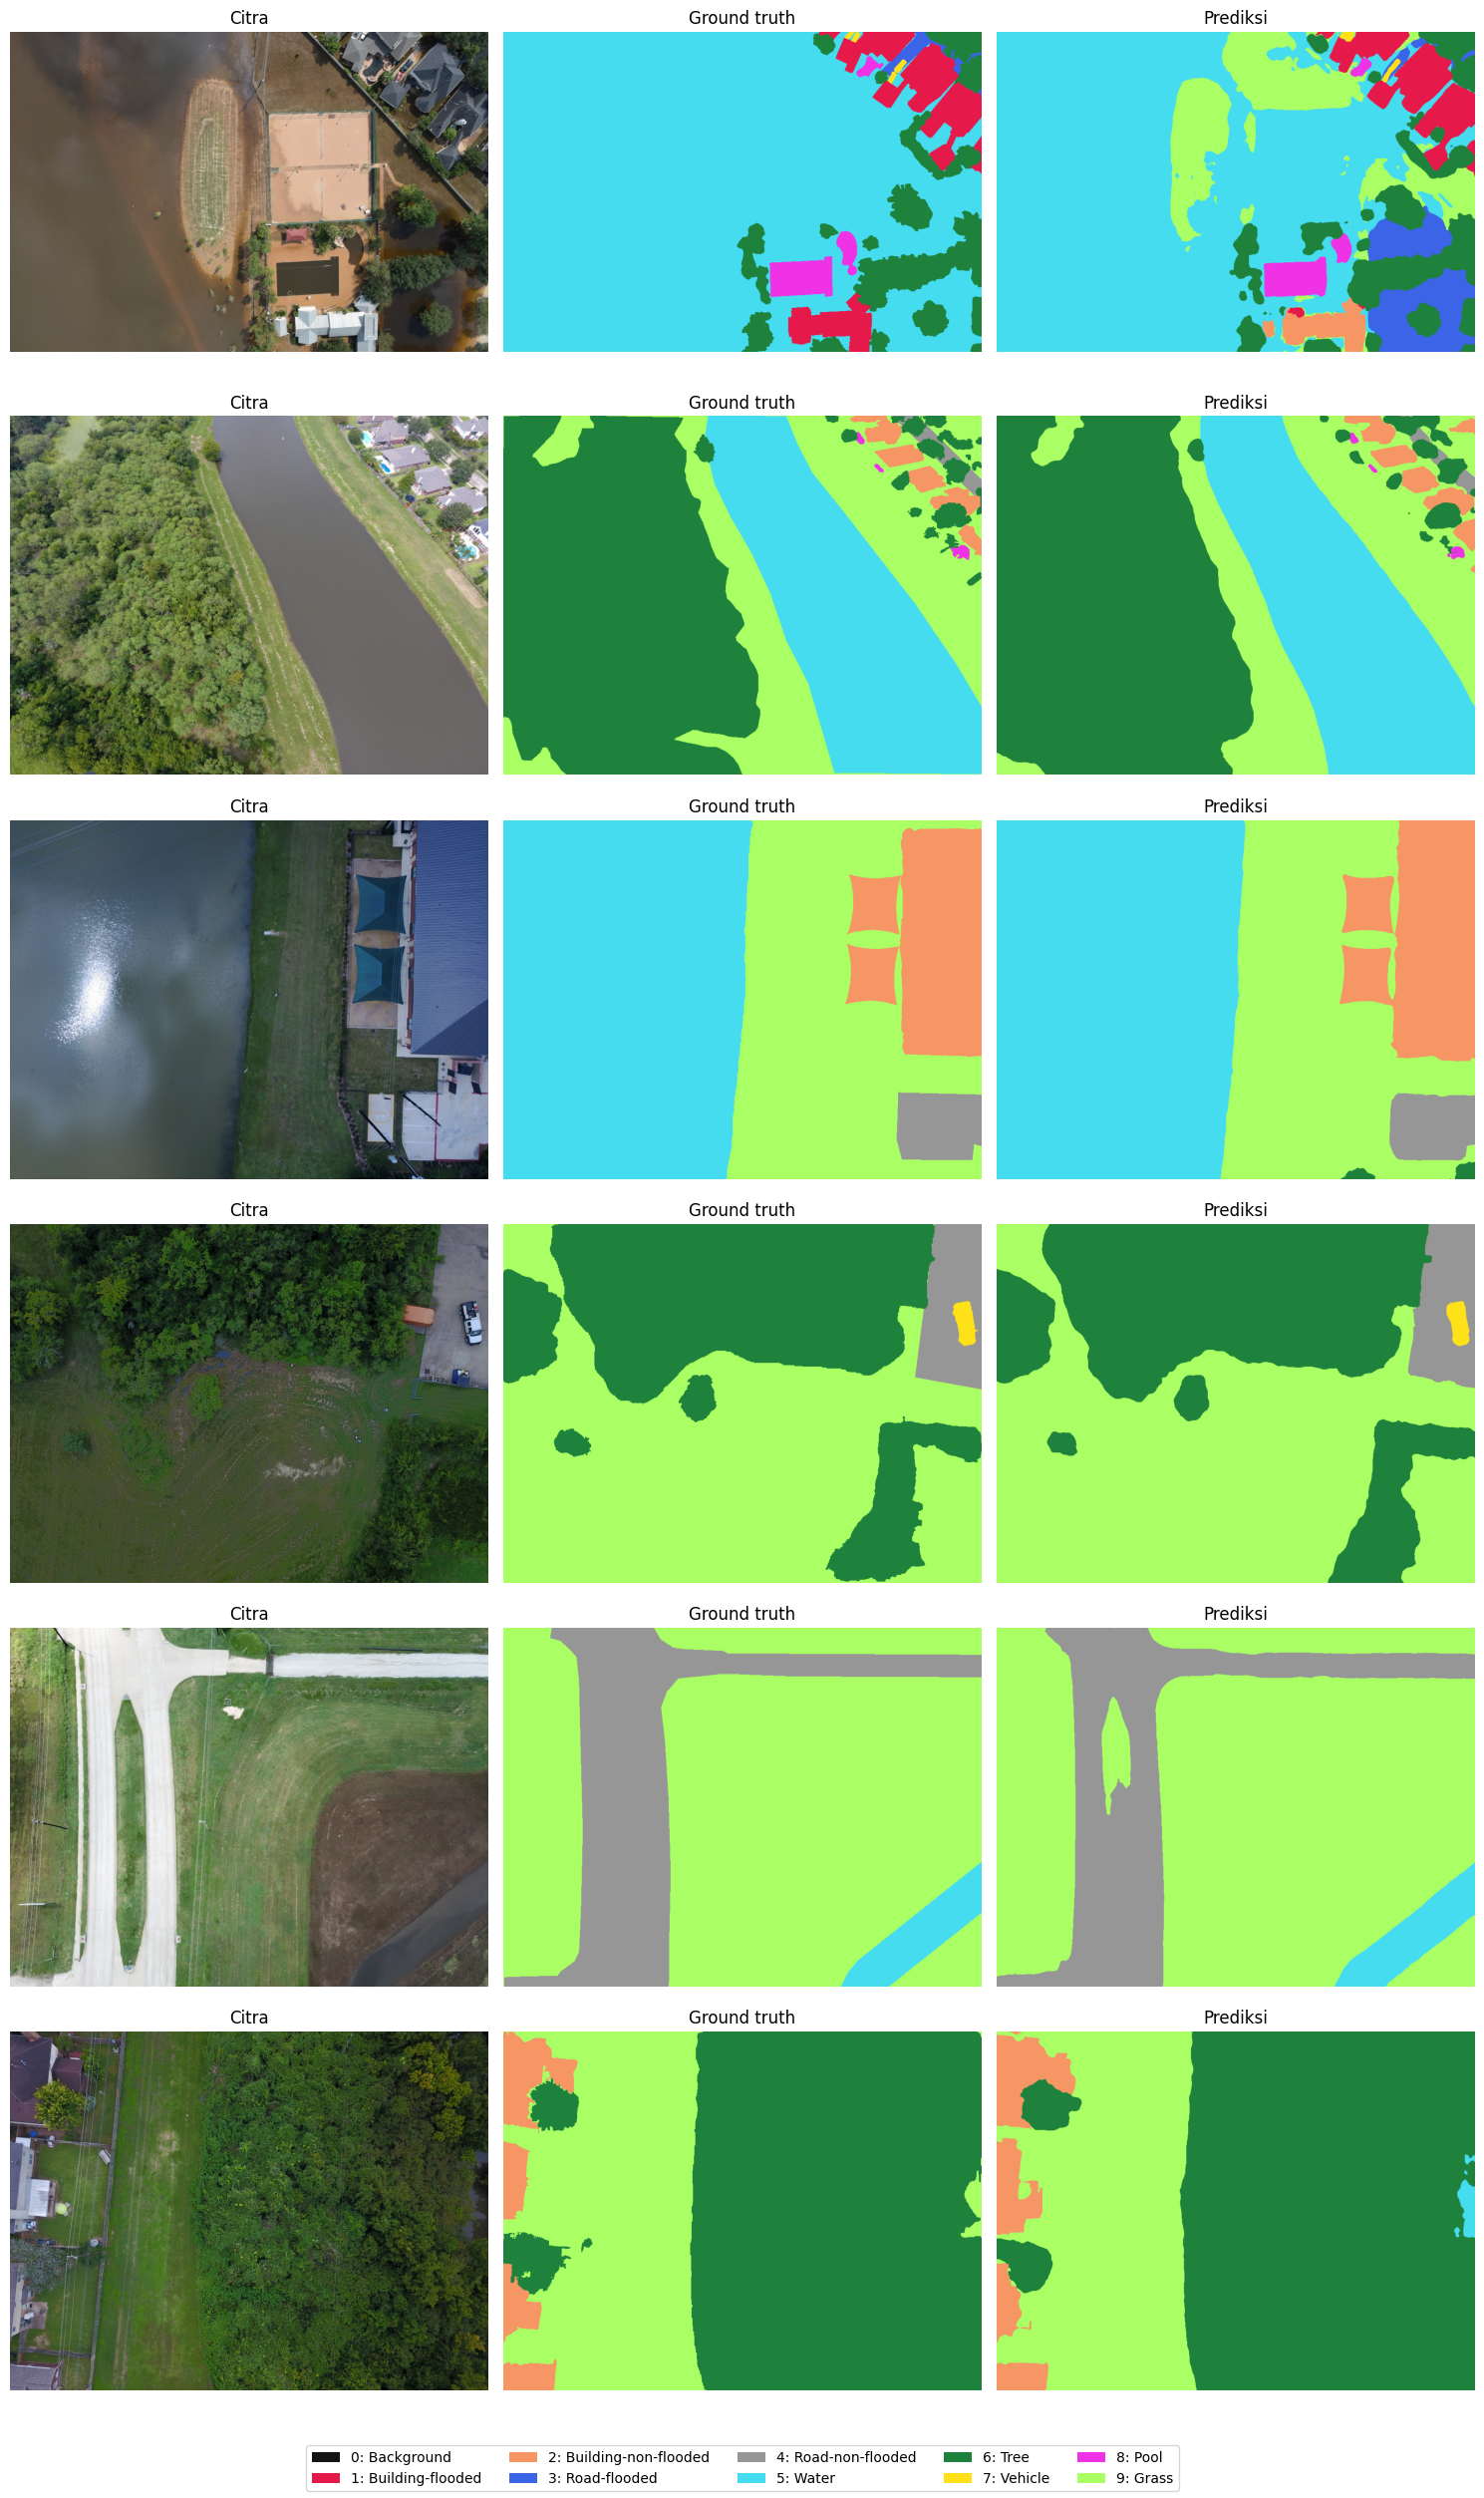

In [15]:
# Kolom: citra | ground truth | prediksi. Sampel dipilih tetap (seed) dari test set.
ds = test_ds if test_ds else val_ds
rng = random.Random(7)
idxs = rng.sample(range(len(ds)), min(6, len(ds)))
fig, axes = plt.subplots(len(idxs), 3, figsize=(15, 4.2 * len(idxs)))
axes = np.atleast_2d(axes)
for r_i, i in enumerate(idxs):
    x, y = ds[i]
    with torch.no_grad():
        p = predict_probs(model, x[None].to(device)).argmax(1)[0].cpu().numpy()
    img = ((x.numpy().transpose(1, 2, 0) * STD + MEAN) * 255).clip(0, 255).astype(np.uint8)
    gt = y.numpy().astype(np.uint8)
    for c, (t, a) in enumerate([("Citra", img), ("Ground truth", colorize(gt)),
                                ("Prediksi", colorize(p.astype(np.uint8)))]):
        axes[r_i, c].imshow(a); axes[r_i, c].set_title(t); axes[r_i, c].axis("off")
fig.legend(handles=LEGEND, loc="lower center", ncol=5, fontsize=10)
plt.tight_layout(rect=(0, 0.03, 1, 1)); savefig("05_qualitative"); plt.show()

In [16]:
# ---- Efisiensi: parameter, FLOPs/MACs (total, per resolusi, encoder vs decoder), dan kecepatan inferensi ----
# Konvensi: 1 MAC (multiply-accumulate) = 2 FLOPs. Banyak paper segmentasi menulis "FLOPs/GFLOPs" padahal
# angkanya MACs, jadi keduanya dilaporkan terpisah di sini. Yang dihitung hanya konv/linear/matmul (norm, aktivasi,
# resize bilinear, pooling diabaikan; konvensi yang sama dengan thop/fvcore/ptflops).
from torch.utils.flop_counter import FlopCounterMode

W_ = CFG["CACHE_LONG_SIDE"]; H_ = int(round(W_ * 0.75 / 32) * 32)          # resolusi evaluasi (sisi panjang 1024 -> tinggi 768, lebar 1024)
EFF_RES = sorted({(512, 512), (H_, W_), (2 * H_, 2 * W_)})                   # (tinggi, lebar)
net_ = model
net_.eval()

def count_flops(fn, x):                       # total FLOPs (1 MAC = 2 FLOPs) menurut PyTorch FlopCounterMode
    with torch.no_grad(), FlopCounterMode(display=False) as fc:
        fn(x)
    return fc.get_total_flops()

def count_macs_hooks(net, x):                 # pemeriksa independen: MACs konv + linear lewat forward hook
    tot = {"conv": 0, "linear": 0}
    def conv_hook(m, i, o): tot["conv"] += o.numel() * (m.in_channels // m.groups) * m.kernel_size[0] * m.kernel_size[1]
    def lin_hook(m, i, o):  tot["linear"] += o.numel() * m.in_features
    hs = [m.register_forward_hook(conv_hook) for m in net.modules() if isinstance(m, nn.Conv2d)] + \
         [m.register_forward_hook(lin_hook) for m in net.modules() if isinstance(m, nn.Linear)]
    try:
        with torch.no_grad():
            net(x)
    finally:
        for h in hs:
            h.remove()
    return tot["conv"] + tot["linear"]

# ---- 1) Parameter ----
n_total = sum(p.numel() for p in net_.parameters()) / 1e6
n_train = sum(p.numel() for p in net_.parameters() if p.requires_grad) / 1e6

# ---- 2) FLOPs/MACs per resolusi ----
rows = []
for (h, w) in EFF_RES:
    x = torch.randn(1, 3, h, w, device=device)
    try:
        macs_hook = count_macs_hooks(net_, x)
        macs = count_flops(net_, x) / 2
    except RuntimeError as e:                 # mis. out-of-memory pada resolusi besar
        print(f"  lewati {h}x{w}: {type(e).__name__}"); continue
    rows.append(dict(resolusi=f"{w}x{h}", H=h, W=w, GMACs=macs / 1e9, GFLOPs=2 * macs / 1e9,
                     GMACs_hook=macs_hook / 1e9, selisih_hook_pct=100 * (macs_hook - macs) / macs))
    del x
    if device.type == "cuda": torch.cuda.empty_cache()
eff_tab = pd.DataFrame(rows)
main = next(r for r in rows if (r["H"], r["W"]) == (H_, W_))

# ---- 3) Rincian encoder vs decoder pada resolusi evaluasi ----
bb = net_.net.encoder                         # encoder ConvNeXt-Nano
xm = torch.randn(1, 3, H_, W_, device=device)
with torch.autocast(device.type, dtype=torch.float16, enabled=USE_AMP):
    enc_macs = count_flops(bb, xm) / 2
dec_macs = main["GMACs"] * 1e9 - enc_macs
enc_p = sum(p.numel() for p in bb.parameters()) / 1e6
split = dict(encoder=dict(params_M=round(enc_p, 2), GMACs=round(enc_macs / 1e9, 2), persen_GMACs=round(100 * enc_macs / (main["GMACs"] * 1e9), 1)),
             decoder_dan_lainnya=dict(params_M=round(n_total - enc_p, 2), GMACs=round(dec_macs / 1e9, 2),
                                      persen_GMACs=round(100 * dec_macs / (main["GMACs"] * 1e9), 1)))

# ---- 4) Kecepatan inferensi (batch 1, resolusi evaluasi, AMP mengikuti USE_AMP) ----
dummy = torch.randn(1, 3, H_, W_, device=device)
with torch.no_grad():
    for _ in range(5):
        with torch.autocast(device.type, dtype=torch.float16, enabled=USE_AMP): net_(dummy)
    if device.type == "cuda": torch.cuda.synchronize()
    n_it = 50 if device.type == "cuda" else 3
    t0 = time.time()
    for _ in range(n_it):
        with torch.autocast(device.type, dtype=torch.float16, enabled=USE_AMP): net_(dummy)
    if device.type == "cuda": torch.cuda.synchronize()
    dt = (time.time() - t0) / n_it
fps = 1.0 / dt

# ---- 5) Ringkasan ----
key = f"{W_}x{H_}"
eff = {"model": CFG["MODEL"], "params_M": round(n_total, 2), "params_trainable_M": round(n_train, 2),
       "size_MB_fp32": round(n_total * 4, 1),
       f"GMACs_{key}": round(main["GMACs"], 2), f"GFLOPs_{key}": round(main["GFLOPs"], 2),
       f"FPS_{key}": round(fps, 1), f"latency_ms_{key}": round(1000 * dt, 1),
       "by_resolution": {r["resolusi"]: dict(GMACs=round(r["GMACs"], 2), GFLOPs=round(r["GFLOPs"], 2)) for r in rows},
       "encoder_vs_decoder": split,
       "metode": "torch.utils.flop_counter.FlopCounterMode",
       "konvensi": "1 MAC = 2 FLOPs; hanya konv/linear/matmul (norm, aktivasi, resize bilinear diabaikan)",
       "device": str(device), "amp": USE_AMP, "n_iter_fps": n_it}
print(f"Model: {CFG['MODEL']} | parameter: {n_total:.2f} M (trainable {n_train:.2f} M, ~{n_total*4:.1f} MB fp32)")
print("\nKompleksitas per resolusi input:")
print(eff_tab[["resolusi", "GMACs", "GFLOPs", "GMACs_hook", "selisih_hook_pct"]].round(2).to_string(index=False))
print("Catatan: GFLOPs = 2 × GMACs. Kolom GMACs_hook adalah verifikasi independen yang hanya menghitung lapisan konvolusi dan linear; "
      "selisih kecil menunjukkan hasil yang konsisten dengan FlopCounterMode.")
print(f"\nRincian komputasi pada {key}:")
print(f"  Encoder           : {split['encoder']['params_M']} M parameter | {split['encoder']['GMACs']} GMACs ({split['encoder']['persen_GMACs']}%)")
print(f"  Decoder + lainnya : {split['decoder_dan_lainnya']['params_M']} M parameter | {split['decoder_dan_lainnya']['GMACs']} GMACs ({split['decoder_dan_lainnya']['persen_GMACs']}%)")
print(f"\nKecepatan @ {key}, batch 1: {fps:.1f} FPS ({1000*dt:.1f} ms/citra) di {device} | AMP={USE_AMP} | {n_it} iterasi")
json.dump(eff, open(EXP_DIR / "efficiency.json", "w"), indent=2)
eff_tab.round(3).to_csv(EXP_DIR / "efficiency_by_resolution.csv", index=False)


Model: upernet-convnext-nano | parameter: 17.72 M (trainable 17.72 M, ~70.9 MB fp32)

Kompleksitas per resolusi input:
 resolusi  GMACs  GFLOPs  GMACs_hook  selisih_hook_pct
  512x512  26.27   52.53       26.27               0.0
 1024x768  78.79  157.58       78.79               0.0
2048x1536 315.15  630.30      315.15               0.0
Catatan: GFLOPs = 2 × GMACs. Kolom GMACs_hook adalah verifikasi independen yang hanya menghitung lapisan konvolusi dan linear; selisih kecil menunjukkan hasil yang konsisten dengan FlopCounterMode.

Rincian komputasi pada 1024x768:
  Encoder           : 14.95 M parameter | 38.32 GMACs (48.6%)
  Decoder + lainnya : 2.77 M parameter | 40.47 GMACs (51.4%)

Kecepatan @ 1024x768, batch 1: 30.5 FPS (32.8 ms/citra) di cuda | AMP=True | 50 iterasi
